# Project 2 — Credit Card Fraud: Ranking Transactions for Investigation

**Course:** DSC8307 Data Mining, Modeling and Analytics — Advent 2026 (Assignment 2)
**Task:** Build an anomaly detector that prioritizes transactions for fraud investigation, then
evaluate its ranking against the withheld fraud labels.

**Data:** `creditcard.csv` — 284,807 European card transactions over two days in September
2013 (Dal Pozzolo et al., 2015; ULB Machine Learning Group), 492 of them fraudulent (0.172%).
Features `V1..V28` are anonymized PCA components; only `Time` and `Amount` are raw.

**Framing.** The deliverable is a *ranking*: an investigation team can review only the top-k
transactions, so we evaluate every method by how many frauds it places near the top
(precision@k, recall@k, average precision), not by a single accuracy figure. Fraud labels are
**withheld from all unsupervised methods** and used only (a) to evaluate rankings and (b) to
train the classification-based approach that the brief asks us to compare against.

Structure: data understanding → justified preparation → evaluation protocol → statistical
outlier baseline → cluster-based detectors → classification-based detectors → comparison → why
"unusual" is not "fraudulent".


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.covariance import EmpiricalCovariance
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import IsolationForest, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             silhouette_score)

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 130)


## 1. Data Loading
The CSV is shipped gzip-compressed (`data/creditcard.csv.gz`) to stay under GitHub's 100 MB
file limit; pandas decompresses transparently.


In [2]:
df = pd.read_csv("data/creditcard.csv.gz")
print("Shape:", df.shape)
df.head()


Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
print("Missing values:", int(df.isna().sum().sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()),
      "| of which labelled fraud:", int(df[df["Class"] == 1].duplicated().sum()))
df.describe().T[["mean", "std", "min", "50%", "max"]].round(3)


Missing values: 0


Exact duplicate rows: 1081 | of which labelled fraud: 19


,mean,std,min,50%,max
Time,94813.860,47488.146,0.000,84692.000,172792.000
V1,0.000,1.959,-56.408,0.018,2.455
V2,0.000,1.651,-72.716,0.065,22.058
V3,-0.000,1.516,-48.326,0.180,9.383
V4,0.000,1.416,-5.683,-0.020,16.875
V5,0.000,1.380,-113.743,-0.054,34.802
V6,0.000,1.332,-26.161,-0.274,73.302
V7,-0.000,1.237,-43.557,0.040,120.589
V8,0.000,1.194,-73.217,0.022,20.007
V9,-0.000,1.099,-13.434,-0.051,15.595


## 2. Exploratory Data Analysis & Data Report

### 2.1 Class balance


Class
0    284315
1       492
Fraud rate: 0.00173  (0.173%)  -> 1 fraud per 578 transactions


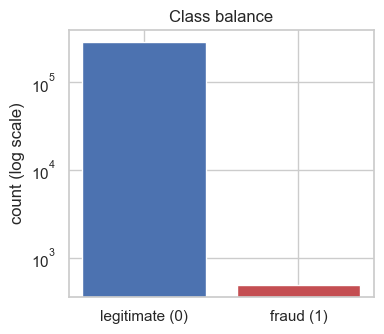

In [4]:
counts = df["Class"].value_counts()
print(counts.to_string())
print(f"Fraud rate: {df['Class'].mean():.5f}  ({df['Class'].mean()*100:.3f}%)  -> 1 fraud per {int(1/df['Class'].mean())} transactions")

fig, ax = plt.subplots(figsize=(4, 3.5))
ax.bar(["legitimate (0)", "fraud (1)"], counts.values, color=["#4C72B0", "#C44E52"])
ax.set_yscale("log")
ax.set_ylabel("count (log scale)")
ax.set_title("Class balance")
plt.tight_layout()
plt.show()


This is an extreme imbalance (about 1 in 580). Two consequences shape the whole notebook:
accuracy and even ROC-AUC are nearly uninformative (a detector can reach 99.8% accuracy by
flagging nothing), so we lead with **average precision (PR-AUC)** and **precision/recall at an
investigation budget k**; and any split or cross-validation must be **stratified** so that each
fold retains enough frauds to evaluate on.

### 2.2 Time
`Time` is seconds since the first transaction and spans just under 48 hours. We convert it to an
*hour-of-day-like* index, `(Time // 3600) % 24`. The absolute clock offset of the first
transaction is unknown, so this is "hour since the start, modulo 24" — but because the window is
two full days, it still exposes the daily cycle.


Time range: 0 .. 172792 s  = 2.00 days


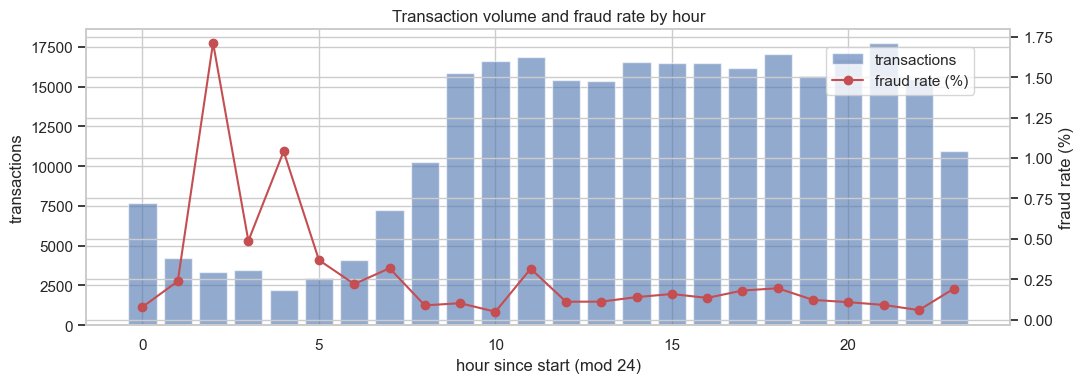

hour,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0,15.0,16.0,17.0,18.0,19.0,20.0,21.0,22.0,23.0
transactions,7695.000,4220.000,3328.000,3492.000,2209.000,2990.000,4101.000,7243.000,10276.000,15838.000,16598.000,16856.000,15420.00,15365.000,16570.000,16461.000,16453.000,16166.000,17039.000,15649.000,16756.000,17703.00,15441.000,10938.000
frauds,6.000,10.000,57.000,17.000,23.000,11.000,9.000,23.000,9.000,16.000,8.000,53.000,17.00,17.000,23.000,26.000,22.000,29.000,33.000,19.000,18.000,16.00,9.000,21.000
fraud_rate_pct,0.078,0.237,1.713,0.487,1.041,0.368,0.219,0.318,0.088,0.101,0.048,0.314,0.11,0.111,0.139,0.158,0.134,0.179,0.194,0.121,0.107,0.09,0.058,0.192


In [5]:
print(f"Time range: {df['Time'].min():.0f} .. {df['Time'].max():.0f} s  = {df['Time'].max()/86400:.2f} days")
df["hour"] = (df["Time"] // 3600) % 24

by_hour = df.groupby("hour").agg(transactions=("Class", "size"), frauds=("Class", "sum"))
by_hour["fraud_rate_pct"] = 100 * by_hour["frauds"] / by_hour["transactions"]

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(by_hour.index, by_hour["transactions"], color="#4C72B0", alpha=0.6, label="transactions")
ax1.set_xlabel("hour since start (mod 24)"); ax1.set_ylabel("transactions")
ax2 = ax1.twinx()
ax2.plot(by_hour.index, by_hour["fraud_rate_pct"], color="#C44E52", marker="o", label="fraud rate (%)")
ax2.set_ylabel("fraud rate (%)")
ax1.set_title("Transaction volume and fraud rate by hour")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88))
plt.tight_layout()
plt.show()
by_hour.round(3).T


Legitimate volume follows a clear day/night cycle, while fraud does not fall off at night — so
the **fraud *rate* peaks in the small hours** (roughly 1–1.5% in hours 2 and 4 versus ≈0.1% in
daytime). Hour is therefore a legitimately useful feature. It also previews the central message
of Section 9: night-time transactions are *unusual* relative to the bulk, yet the overwhelming
majority of them are still legitimate.

### 2.3 Amount


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.29,250.11,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.21,256.68,0.0,1.00,9.25,105.89,2125.87


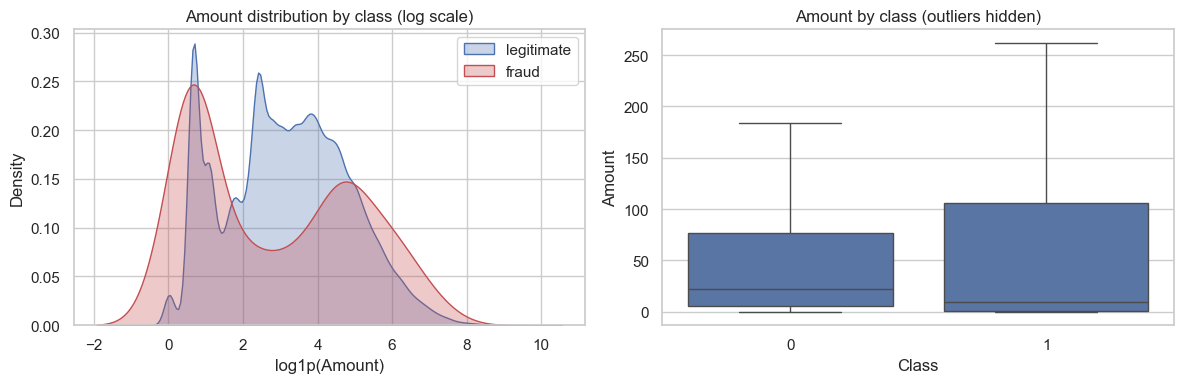

In [6]:
display(df.groupby("Class")["Amount"].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for cls, color, label in [(0, "#4C72B0", "legitimate"), (1, "#C44E52", "fraud")]:
    sns.kdeplot(np.log1p(df.loc[df["Class"] == cls, "Amount"]), ax=axes[0], color=color,
                label=label, fill=True, alpha=0.3, common_norm=False)
axes[0].set_xlabel("log1p(Amount)"); axes[0].set_title("Amount distribution by class (log scale)")
axes[0].legend()
sns.boxplot(data=df, x="Class", y="Amount", ax=axes[1], showfliers=False)
axes[1].set_title("Amount by class (outliers hidden)")
plt.tight_layout()
plt.show()


`Amount` is extremely right-skewed (median ≈ 22 EUR, max > 25,000 EUR), which motivates a
`log1p` transform before any distance-based method. Frauds are *not* simply "large purchases":
their median amount (≈ 10 EUR) is **lower** than for legitimate transactions, with a bimodal
pattern — many tiny test-charges and a tail of larger ones. Amount alone would be a poor fraud
ranker.

### 2.4 The anonymized components
`V1..V28` are already principal components of the original (confidential) features: they are
centred, mutually uncorrelated and ordered by variance. This has three implications we respect
later: no further PCA is needed; no domain feature engineering is possible (a real limitation of
this dataset); and the squared Euclidean distance after standardization is almost the same thing
as the Mahalanobis distance (Section 5). A few components separate the classes visibly:


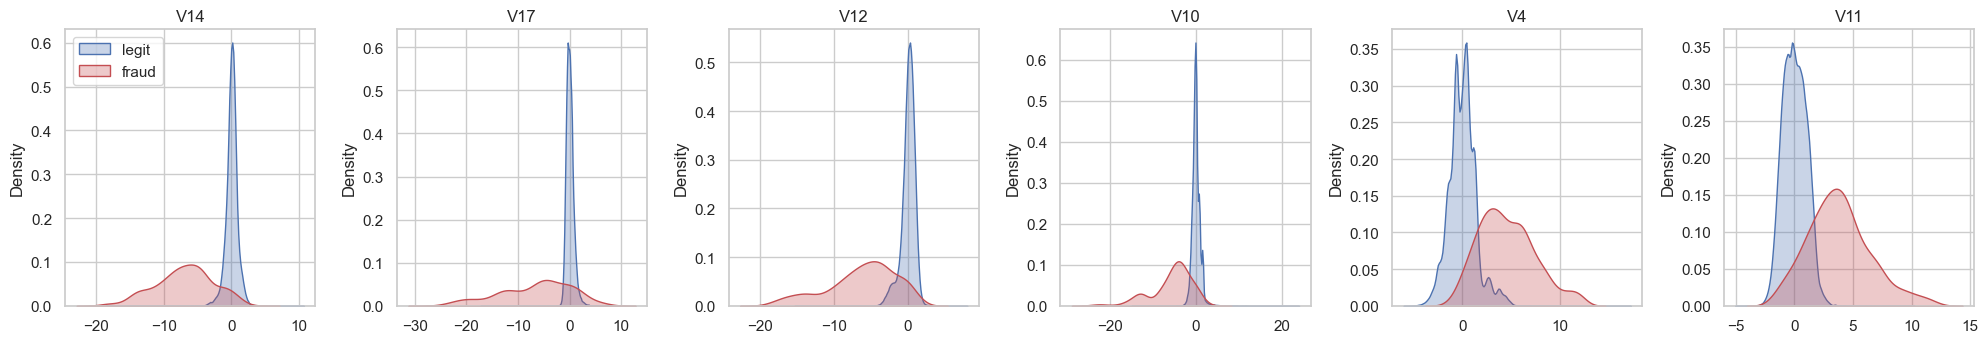

Standardized mean difference (fraud vs legit), top 8 components:
V17    7.86
V14    7.29
V12    6.28
V10    5.22
V16    4.73
V3     4.65
V7     4.51
V11    3.73


In [7]:
show = ["V14", "V17", "V12", "V10", "V4", "V11"]
fig, axes = plt.subplots(1, 6, figsize=(20, 3.6))
for ax, col in zip(axes, show):
    for cls, color, label in [(0, "#4C72B0", "legit"), (1, "#C44E52", "fraud")]:
        sns.kdeplot(df.loc[df["Class"] == cls, col], ax=ax, color=color, label=label,
                    fill=True, alpha=0.3, common_norm=False)
    ax.set_title(col); ax.set_xlabel("")
axes[0].legend()
plt.tight_layout()
plt.show()

v_cols = [f"V{i}" for i in range(1, 29)]
sep = (df.groupby("Class")[v_cols].mean().diff().iloc[1].abs() / df[v_cols].std()).sort_values(ascending=False)
print("Standardized mean difference (fraud vs legit), top 8 components:")
print(sep.head(8).round(2).to_string())


## 3. Data Preparation (with justification)

1. **Drop exact duplicate rows** (1,081, including 19 labelled fraud). Identical rows across
   all 31 columns are almost certainly repeated records rather than independent events; keeping
   them would let the same transaction appear in both training and test splits and inflate
   every score.
2. **`log1p(Amount)`** — removes the heavy right skew (§2.3) so that a single 25,000 EUR
   purchase does not dominate Euclidean/Mahalanobis distances.
3. **`hour`** (§2.2) replaces raw `Time`: raw seconds-since-start encode *which day* rather than
   *when in the day*, which would not generalize beyond this two-day window.
4. **Features:** `V1..V28`, `log_amount`, `hour` (30 columns). **Standardize** all of them with
   statistics fitted on the training split only — the V components have very different
   variances (V1 ≈ 2, V28 ≈ 0.1), and distance-based detectors would otherwise be driven by the
   first few components.
5. **One stratified 70/30 split shared by every method.** All detectors — statistical,
   cluster-based, classification-based — are fitted on the same training rows and ranked on the
   same ≈ 85k test rows (≈ 142 test frauds), so their scores are directly comparable.
   Unsupervised detectors never see `Class`.


In [8]:
df = df.drop_duplicates().reset_index(drop=True)
df["log_amount"] = np.log1p(df["Amount"])
FEATURES = v_cols + ["log_amount", "hour"]

X = df[FEATURES].values
y = df["Class"].values
print("After de-duplication:", df.shape, "| frauds:", int(y.sum()), f"| rate: {y.mean():.5f}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)
print(f"Train: {X_train_s.shape}  frauds={int(y_train.sum())}   Test: {X_test_s.shape}  frauds={int(y_test.sum())}")


After de-duplication: (283726, 33) | frauds: 473 | rate: 0.00167


Train: (198608, 30)  frauds=331   Test: (85118, 30)  frauds=142


## 4. Evaluation Protocol (ranking against withheld labels)

Every detector outputs an **anomaly score** per test transaction (higher = more suspicious). We
sort by score and ask:

- **Average precision (AP / PR-AUC)** — headline metric; summarizes precision across all recall
  levels and, unlike ROC-AUC, is sensitive to how the ≈142 frauds rank among ≈85k legitimate
  rows.
- **ROC-AUC** — reported for completeness; expect it to be high for almost everything.
- **Precision@k** for k = 100, 500, 1000 — "if investigators review the top k, what fraction are
  fraud?" — and **Recall@1000** — "what share of all frauds is caught within a 1000-case
  budget?". k = 1000 is ≈1.2% of the test set, a realistic daily review load.

The reference point for every metric is a **random ranking**, whose precision equals the base
rate (≈0.0017).


In [9]:
def precision_at_k(y_true, score, k):
    top = np.argsort(-score)[:k]
    return y_true[top].mean()

def recall_at_k(y_true, score, k):
    top = np.argsort(-score)[:k]
    return y_true[top].sum() / y_true.sum()

def evaluate(name, score, family):
    return {
        "method": name, "family": family,
        "AP": average_precision_score(y_test, score),
        "ROC_AUC": roc_auc_score(y_test, score),
        "P@100": precision_at_k(y_test, score, 100),
        "P@500": precision_at_k(y_test, score, 500),
        "P@1000": precision_at_k(y_test, score, 1000),
        "R@1000": recall_at_k(y_test, score, 1000),
    }

scores = {}      # name -> anomaly score on the test set
results = []     # rows for the comparison table

scores["Random ranking"] = rng.random(len(y_test))
results.append(evaluate("Random ranking", scores["Random ranking"], "reference"))
print(f"Base rate in test set: {y_test.mean():.5f}")
pd.DataFrame(results).set_index("method").round(4)


Base rate in test set: 0.00167


,family,AP,ROC_AUC,P@100,P@500,P@1000,R@1000
method,,,,,,,
Random ranking,reference,0.002,0.4979,0.01,0.004,0.004,0.0282


## 5. Statistical Outlier Baseline

The simplest possible detector: how far is a transaction from the centre of *all* training
transactions, measured in standard deviations?

- **max |z|** — the single most extreme standardized feature (univariate outlier rule, like
  a 3-sigma test applied per column).
- **sum of z²** — squared Euclidean distance from the mean in standardized space (all features
  jointly).
- **Mahalanobis distance** — the same idea but accounting for feature covariance, fitted on the
  training split. Because `V1..V28` are already uncorrelated PCA components, we expect it to be
  almost identical to the sum of z² — a useful check that the covariance step adds little here.


In [10]:
scores["Univariate max |z|"] = np.abs(X_test_s).max(axis=1)
scores["Sum of z^2"] = (X_test_s ** 2).sum(axis=1)
cov = EmpiricalCovariance().fit(X_train_s)
scores["Mahalanobis distance"] = cov.mahalanobis(X_test_s)

for name in ["Univariate max |z|", "Sum of z^2", "Mahalanobis distance"]:
    results.append(evaluate(name, scores[name], "statistical baseline"))
print("Spearman correlation between Mahalanobis and sum-of-z^2 rankings:",
      round(pd.Series(scores["Mahalanobis distance"]).corr(pd.Series(scores["Sum of z^2"]), method="spearman"), 4))
pd.DataFrame(results).set_index("method").round(4)


Spearman correlation between Mahalanobis and sum-of-z^2 rankings: 0.9937


,family,AP,ROC_AUC,P@100,P@500,P@1000,R@1000
method,,,,,,,
Random ranking,reference,0.0020,0.4979,0.01,0.004,0.004,0.0282
Univariate max |z|,statistical baseline,0.0847,0.9309,0.19,0.104,0.078,0.5493
Sum of z^2,statistical baseline,0.1180,0.9471,0.25,0.110,0.084,0.5915
Mahalanobis distance,statistical baseline,0.1173,0.9467,0.25,0.108,0.084,0.5915


Even this label-free baseline is far from useless: Mahalanobis distance reaches ROC-AUC ≈ 0.95
and puts about 25 frauds in its top 100 (precision@100 ≈ 0.25, i.e. ~150x the base rate) and
catches ≈ 59% of frauds within a 1000-case budget. The univariate rule is clearly weaker —
fraud shows up as a *combination* of moderately unusual components, not one extreme value. As
predicted, Mahalanobis and sum-of-z² are practically the same ranking (Spearman ≈ 1.0), because
the PCA components carry no covariance to correct for.

**Statistical baseline to beat: Mahalanobis distance, AP ≈ 0.12.**


## 6. Cluster-Based Anomaly Detection

**Why a cluster-based approach?** Fraud labels are expensive, delayed (chargebacks arrive weeks
later) and incomplete; a detector that needs *no labels* can run from day one and can surface
*new* fraud patterns. Cluster-based detection models what "normal" looks like as a small number
of dense groups and scores each transaction by how far it falls from the nearest group — a
richer notion of "unusual" than distance from a single global mean (Section 5).

**Why not DBSCAN / LOF here?** Both need pairwise-neighbourhood computations that scale poorly
to ≈200k x 30 (memory and time), and their key hyper-parameters (`eps`, `min_samples`, number of
neighbours) cannot be tuned without labels. K-Means and Gaussian mixtures scale linearly and
give a continuous anomaly score, which is what a ranking task needs.

### 6.1 K-Means: distance to the nearest centroid
We sweep k and report (a) the silhouette on a 20k-row sample — is there real cluster structure? —
and (b) the ranking quality when the anomaly score is the distance to the nearest centroid.


In [11]:
sample_idx = rng.choice(len(X_train_s), 20000, replace=False)
km_rows = []
km_models = {}
for k in [2, 4, 8, 16]:
    km = KMeans(n_clusters=k, n_init=5, random_state=RANDOM_STATE).fit(X_train_s)
    km_models[k] = km
    score = km.transform(X_test_s).min(axis=1)
    scores[f"K-Means distance (k={k})"] = score
    row = evaluate(f"K-Means distance (k={k})", score, "cluster-based")
    row["silhouette_train_sample"] = silhouette_score(X_train_s[sample_idx], km.predict(X_train_s[sample_idx]))
    km_rows.append(row)
km_table = pd.DataFrame(km_rows).set_index("method")
km_table.round(4)


,family,AP,ROC_AUC,P@100,P@500,P@1000,R@1000,silhouette_train_sample
method,,,,,,,,
K-Means distance (k=2),cluster-based,0.1183,0.9483,0.25,0.110,0.084,0.5915,0.0697
K-Means distance (k=4),cluster-based,0.1177,0.9499,0.25,0.110,0.084,0.5915,0.0675
K-Means distance (k=8),cluster-based,0.1399,0.9530,0.25,0.144,0.101,0.7113,0.0630
K-Means distance (k=16),cluster-based,0.0791,0.9474,0.06,0.112,0.094,0.6620,0.0730


Silhouettes of ≈ 0.07 for every k say there are **no well-separated clusters** in transaction
space: "normal" is one broad, dense cloud. Consequently K-Means with small k behaves almost
exactly like the Mahalanobis baseline (same AP, same precision@k), while **k = 8** adds a little
by letting the centroids follow the cloud's shape (AP ≈ 0.14, recall@1000 ≈ 0.71). Beyond that
(k = 16) centroids start to sit on sparse regions and the ranking degrades — we keep k = 8.

### 6.2 Gaussian Mixture: negative log-likelihood
A soft, probabilistic generalization of K-Means: each component has its own covariance, and the
anomaly score is how *improbable* a transaction is under the fitted mixture.


In [12]:
gmm_rows = []
for n in [4, 8]:
    gmm = GaussianMixture(n_components=n, covariance_type="full", random_state=RANDOM_STATE).fit(X_train_s)
    score = -gmm.score_samples(X_test_s)
    scores[f"GMM neg. log-likelihood (n={n})"] = score
    gmm_rows.append(evaluate(f"GMM neg. log-likelihood (n={n})", score, "cluster-based"))
pd.DataFrame(gmm_rows).set_index("method").round(4)


,family,AP,ROC_AUC,P@100,P@500,P@1000,R@1000
method,,,,,,,
GMM neg. log-likelihood (n=4),cluster-based,0.1369,0.9370,0.26,0.150,0.088,0.6197
GMM neg. log-likelihood (n=8),cluster-based,0.2612,0.9337,0.35,0.146,0.085,0.5986


The mixture is the strongest label-free detector: with 8 components AP roughly doubles relative
to K-Means (≈ 0.26) and precision@100 rises to ≈ 0.35. Allowing each component its own
covariance lets the model describe the "normal" cloud's local shape, so transactions that are
unusual *for their neighbourhood* stand out.

### 6.3 Reference: Isolation Forest
Not cluster-based, but the standard unsupervised anomaly detector from the lectures; included
so the cluster-based results can be placed in context.


In [13]:
iso = IsolationForest(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1).fit(X_train_s)
scores["Isolation Forest"] = -iso.score_samples(X_test_s)
iso_row = evaluate("Isolation Forest", scores["Isolation Forest"], "unsupervised reference")
results += km_rows + gmm_rows + [iso_row]
pd.DataFrame([iso_row]).set_index("method").round(4)


,family,AP,ROC_AUC,P@100,P@500,P@1000,R@1000
method,,,,,,,
Isolation Forest,unsupervised reference,0.1375,0.9402,0.26,0.126,0.089,0.6268


## 7. Classification-Based Anomaly Detection

**Why a classification-based approach?** When (even a modest number of) confirmed fraud labels
exist, they encode *what fraud looks like* — specific combinations of components, amounts and
hours — rather than merely *what is rare*. A supervised model can therefore rank a fraud that
looks superficially ordinary above a legitimate transaction that is merely unusual. The price:
it only learns fraud patterns present in the labelled history, needs continual relabelling as
fraudsters adapt (concept drift), and inherits any bias in which transactions were investigated.

We train two classifiers on the labelled training split and rank the test set by predicted
fraud probability:

- **Logistic Regression** with `class_weight="balanced"` — linear, fast, interpretable.
- **Hist Gradient Boosting** with `class_weight="balanced"` — non-linear interactions.

Both use 3-fold **stratified** cross-validation on the training split (AP) to check stability
before the single test-set evaluation.


In [14]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
classifiers = {
    "Logistic Regression (balanced)": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Hist Gradient Boosting (balanced)": HistGradientBoostingClassifier(
        class_weight="balanced", early_stopping=False, random_state=RANDOM_STATE),
}
clf_rows = []
for name, clf in classifiers.items():
    cv_ap = cross_val_score(clf, X_train_s, y_train, cv=cv, scoring="average_precision")
    clf.fit(X_train_s, y_train)
    scores[name] = clf.predict_proba(X_test_s)[:, 1]
    row = evaluate(name, scores[name], "classification-based")
    row["CV_AP_mean"] = cv_ap.mean()
    row["CV_AP_std"] = cv_ap.std()
    clf_rows.append(row)
    print(f"{name:36s} CV AP = {cv_ap.mean():.3f} +/- {cv_ap.std():.3f}")
results += clf_rows
pd.DataFrame(clf_rows).set_index("method").round(4)


Logistic Regression (balanced)       CV AP = 0.750 +/- 0.022


Hist Gradient Boosting (balanced)    CV AP = 0.835 +/- 0.006


,family,AP,ROC_AUC,P@100,P@500,P@1000,R@1000,CV_AP_mean,CV_AP_std
method,,,,,,,,,
Logistic Regression (balanced),classification-based,0.6911,0.9629,0.86,0.238,0.124,0.8732,0.7496,0.0219
Hist Gradient Boosting (balanced),classification-based,0.7916,0.9760,0.97,0.242,0.125,0.8803,0.8353,0.0065


### 7.1 Sensitivity check: a default setting that silently fails under extreme imbalance
`HistGradientBoostingClassifier` turns on *early stopping* automatically for datasets larger
than 10k rows, carving out 10% of the training data as an internal validation set. With 0.17%
fraud that validation set contains only ≈ 30 frauds, so the stopping rule fires on noise. We
show the effect because it is exactly the kind of assumption that must be checked rather than
trusted:


In [15]:
variants = {
    "HGB default (auto early stopping, unweighted)": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    "HGB no early stopping, unweighted": HistGradientBoostingClassifier(early_stopping=False, random_state=RANDOM_STATE),
    "HGB no early stopping, balanced (used)": classifiers["Hist Gradient Boosting (balanced)"],
}
sens = []
for name, clf in variants.items():
    if name.endswith("(used)"):
        s = scores["Hist Gradient Boosting (balanced)"]
    else:
        s = clf.fit(X_train_s, y_train).predict_proba(X_test_s)[:, 1]
    sens.append({"variant": name, "AP": average_precision_score(y_test, s),
                 "ROC_AUC": roc_auc_score(y_test, s), "P@100": precision_at_k(y_test, s, 100)})
pd.DataFrame(sens).set_index("variant").round(4)


,AP,ROC_AUC,P@100
variant,,,
"HGB default (auto early stopping, unweighted)",0.4735,0.7333,0.76
"HGB no early stopping, unweighted",0.0172,0.5625,0.14
"HGB no early stopping, balanced (used)",0.7916,0.9760,0.97


The default configuration loses a large share of its ranking quality, and switching early
stopping off *without* re-weighting the classes is even worse (the unweighted log-loss is
dominated by the 99.8% majority class). Only the combination used above — no early stopping
plus balanced class weights — is reliable. Logistic Regression has no such hidden switch and
is correspondingly stable across its CV folds.


## 8. Comparison of Approaches


In [16]:
comparison = pd.DataFrame(results).set_index("method")
comparison = comparison[["family", "AP", "ROC_AUC", "P@100", "P@500", "P@1000", "R@1000"]]
comparison.sort_values("AP", ascending=False).round(4)


,family,AP,ROC_AUC,P@100,P@500,P@1000,R@1000
method,,,,,,,
Hist Gradient Boosting (balanced),classification-based,0.7916,0.9760,0.97,0.242,0.125,0.8803
Logistic Regression (balanced),classification-based,0.6911,0.9629,0.86,0.238,0.124,0.8732
GMM neg. log-likelihood (n=8),cluster-based,0.2612,0.9337,0.35,0.146,0.085,0.5986
K-Means distance (k=8),cluster-based,0.1399,0.9530,0.25,0.144,0.101,0.7113
Isolation Forest,unsupervised reference,0.1375,0.9402,0.26,0.126,0.089,0.6268
GMM neg. log-likelihood (n=4),cluster-based,0.1369,0.9370,0.26,0.150,0.088,0.6197
K-Means distance (k=2),cluster-based,0.1183,0.9483,0.25,0.110,0.084,0.5915
Sum of z^2,statistical baseline,0.1180,0.9471,0.25,0.110,0.084,0.5915
K-Means distance (k=4),cluster-based,0.1177,0.9499,0.25,0.110,0.084,0.5915


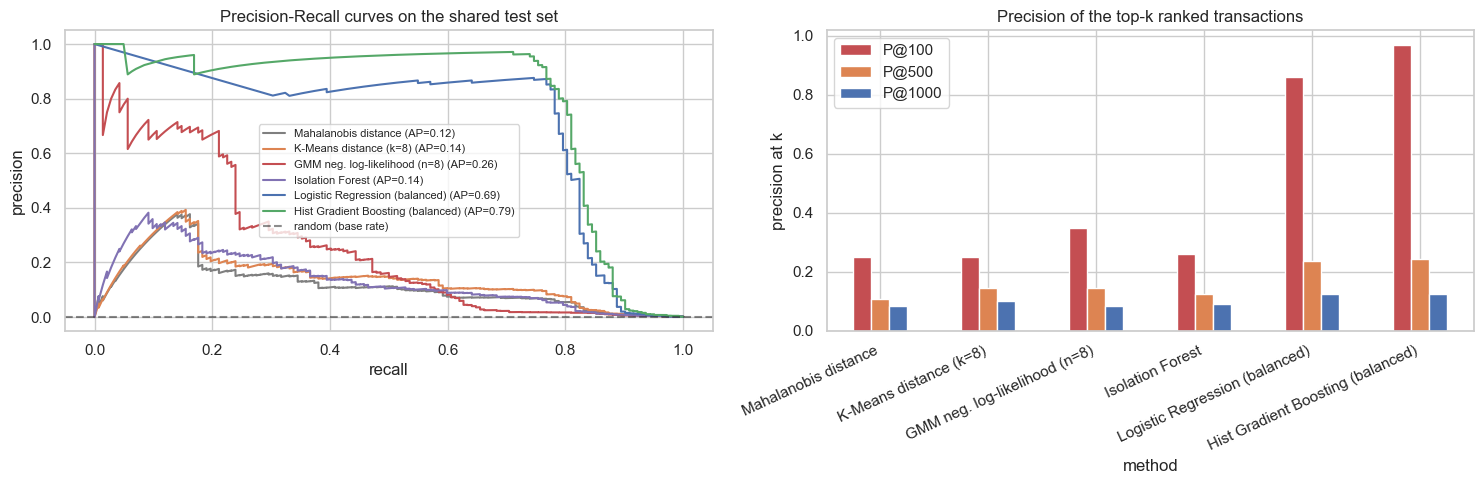

In [17]:
highlight = ["Mahalanobis distance", "K-Means distance (k=8)", "GMM neg. log-likelihood (n=8)",
             "Isolation Forest", "Logistic Regression (balanced)", "Hist Gradient Boosting (balanced)"]
colors = ["#7f7f7f", "#DD8452", "#C44E52", "#8172B3", "#4C72B0", "#55A868"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name, color in zip(highlight, colors):
    p, r, _ = precision_recall_curve(y_test, scores[name])
    axes[0].plot(r, p, label=f"{name} (AP={average_precision_score(y_test, scores[name]):.2f})", color=color)
axes[0].axhline(y_test.mean(), color="k", linestyle="--", alpha=0.5, label="random (base rate)")
axes[0].set_xlabel("recall"); axes[0].set_ylabel("precision")
axes[0].set_title("Precision-Recall curves on the shared test set")
axes[0].legend(fontsize=8)

pk = comparison.loc[highlight, ["P@100", "P@500", "P@1000"]]
pk.plot(kind="bar", ax=axes[1], color=["#C44E52", "#DD8452", "#4C72B0"])
axes[1].set_ylabel("precision at k")
axes[1].set_title("Precision of the top-k ranked transactions")
axes[1].tick_params(axis="x", rotation=25)
plt.setp(axes[1].get_xticklabels(), ha="right")
plt.tight_layout()
plt.show()


**What the comparison shows.**

1. **Every detector beats random by two orders of magnitude at the top of the ranking** — even
   the plain Mahalanobis baseline makes 1 in 4 of its top-100 cases a fraud versus 1 in 600 at
   random. Rarity is genuinely informative about fraud.
2. **Among label-free methods, modelling the *shape* of normal behaviour pays:** K-Means with
   enough centroids edges past the baseline, and the Gaussian mixture roughly doubles AP
   (≈ 0.26) with precision@100 ≈ 0.35. Isolation Forest performs about the same as K-Means. But all of them
   plateau: beyond the first few hundred cases their precision collapses towards 10%, because
   most *unusual* transactions are legitimate (Section 9).
3. **Labels change the game.** Both classifiers reach AP ≈ 0.7–0.8 and put **≈ 85–97 frauds in
   the top 100** (precision@100 ≈ 0.86–0.97) while recovering ≈ 87–88% of all frauds within a
   1000-case budget — roughly three times the AP of the best unsupervised detector. Gradient
   boosting is the single best ranker; Logistic Regression is close behind and far simpler to
   audit.
4. **The two families answer different questions and belong together.** The classification-
   based ranker should drive day-to-day prioritization because it is dramatically more precise
   where investigators actually look (the top of the list). The cluster/density-based ranker
   should run alongside it as a *novelty* channel: it needs no labels, so it can flag emerging
   fraud patterns the supervised model has never seen — and its top cases can be fed back as new
   labels. Choosing *only* the unsupervised approach would waste the labels the bank already
   has; choosing *only* the supervised approach would leave it blind to new attack types.


## 9. Why an Unusual Transaction Is Not Necessarily Fraudulent

Anomaly detection answers "*is this rare relative to the bulk of transactions?*"; fraud is a
question of **intent** that the data can only label after the fact. The two overlap — frauds
are rare and often odd — but they are not the same thing, and this dataset lets us show that
directly.

### 9.1 Evidence 1 — most top-ranked anomalies are legitimate


In [18]:
def top_k_breakdown(name, k=100):
    top = np.argsort(-scores[name])[:k]
    return {"detector": name, "k": k, "frauds_in_top_k": int(y_test[top].sum()),
            "legitimate_in_top_k": int(k - y_test[top].sum())}

pd.DataFrame([top_k_breakdown(n, k) for n in ["Mahalanobis distance", "GMM neg. log-likelihood (n=8)",
                                               "Isolation Forest", "Hist Gradient Boosting (balanced)"]
              for k in [100, 1000]]).set_index(["detector", "k"])


frauds_in_top_k  legitimate_in_top_k
detector                          k                                         
Mahalanobis distance              100                25                   75
                                  1000               84                  916
GMM neg. log-likelihood (n=8)     100                35                   65
                                  1000               85                  915
Isolation Forest                  100                26                   74
                                  1000               89                  911
Hist Gradient Boosting (balanced) 100                97                    3
                                  1000              125                  875

For the purely unsupervised detectors, three-quarters of the 100 *most anomalous* transactions
— and about 90% of the top 1000 — are legitimate. These are real customers doing something
statistically unusual, not criminals.

### 9.2 Evidence 2 — what the legitimate "anomalies" look like


,typical legitimate,legitimate but flagged (top-1000 Mahalanobis),fraud
median amount (EUR),21.9,39.5,11.9
% with amount > 500 EUR,3.2,21.8,9.9
% in night hours (0-5),8.5,8.5,24.6


Share of frauds with amount below 10 EUR: 48.6%


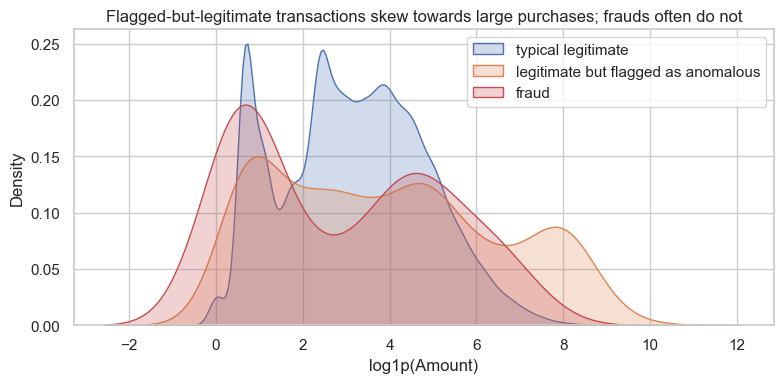

In [19]:
# recover raw amount / hour for the test rows
_, test_idx = train_test_split(np.arange(len(y)), test_size=0.30, stratify=y, random_state=RANDOM_STATE)
amount_test = df["Amount"].values[test_idx]
hour_test = df["hour"].values[test_idx]

top1000 = np.argsort(-scores["Mahalanobis distance"])[:1000]
flagged_legit = top1000[y_test[top1000] == 0]
all_legit = np.where(y_test == 0)[0]
frauds = np.where(y_test == 1)[0]

summary = pd.DataFrame({
    "typical legitimate": [np.median(amount_test[all_legit]), np.mean(amount_test[all_legit] > 500) * 100,
                           np.mean(np.isin(hour_test[all_legit], [0, 1, 2, 3, 4, 5])) * 100],
    "legitimate but flagged (top-1000 Mahalanobis)": [np.median(amount_test[flagged_legit]), np.mean(amount_test[flagged_legit] > 500) * 100,
                                                     np.mean(np.isin(hour_test[flagged_legit], [0, 1, 2, 3, 4, 5])) * 100],
    "fraud": [np.median(amount_test[frauds]), np.mean(amount_test[frauds] > 500) * 100,
              np.mean(np.isin(hour_test[frauds], [0, 1, 2, 3, 4, 5])) * 100],
}, index=["median amount (EUR)", "% with amount > 500 EUR", "% in night hours (0-5)"])
display(summary.round(1))
print(f"Share of frauds with amount below 10 EUR: {np.mean(amount_test[frauds] < 10) * 100:.1f}%")

fig, ax = plt.subplots(figsize=(8, 4))
sns.kdeplot(np.log1p(amount_test[all_legit]), label="typical legitimate", color="#4C72B0", fill=True, alpha=0.25, ax=ax)
sns.kdeplot(np.log1p(amount_test[flagged_legit]), label="legitimate but flagged as anomalous", color="#DD8452", fill=True, alpha=0.25, ax=ax)
sns.kdeplot(np.log1p(amount_test[frauds]), label="fraud", color="#C44E52", fill=True, alpha=0.25, ax=ax)
ax.set_xlabel("log1p(Amount)"); ax.set_title("Flagged-but-legitimate transactions skew towards large purchases; frauds often do not")
ax.legend()
plt.tight_layout()
plt.show()


The legitimate transactions that the anomaly detector flags differ from typical ones mainly by
**size**: they are about seven times as likely to exceed 500 EUR (≈ 22% vs ≈ 3%) and their
median amount is roughly double — a customer buying a laptop, paying a hotel bill, or making a
once-a-year purchase. Notably, they are *not* more nocturnal than typical transactions (≈ 8.5%
in hours 0–5 in both groups), even though frauds are about three times as likely to occur at
night (≈ 25%): one `hour` column among 30 standardized features barely moves a global distance
score, so the detector's notion of "unusual" is driven by the PCA components, not by the clock
— a reminder that a statistical anomaly score does not know which kinds of unusualness matter.
Conversely, roughly **half of all frauds are under 10 EUR**: card testers deliberately make
tiny, ordinary-looking charges precisely so they do *not* look unusual. "Unusual" and
"fraudulent" are correlated, but each contains much that the other does not.

### 9.3 Evidence 3 — the base-rate arithmetic


In [20]:
n_test = len(y_test); n_fraud = int(y_test.sum()); n_legit = n_test - n_fraud
for specificity in [0.99, 0.999]:
    false_alarms = n_legit * (1 - specificity)
    for sensitivity in [0.9]:
        caught = n_fraud * sensitivity
        print(f"specificity {specificity:.1%}, sensitivity {sensitivity:.0%}: "
              f"{caught:.0f} frauds caught vs {false_alarms:.0f} legitimate customers flagged "
              f"-> precision {caught / (caught + false_alarms):.1%}")


specificity 99.0%, sensitivity 90%: 128 frauds caught vs 850 legitimate customers flagged -> precision 13.1%
specificity 99.9%, sensitivity 90%: 128 frauds caught vs 85 legitimate customers flagged -> precision 60.1%


Because frauds are 1 in 600, a detector that is wrong about only 1% of legitimate transactions
still generates roughly **six false alarms for every fraud it catches**; even at 99.9%
specificity the flagged list is still about 40% legitimate. No amount of statistical
"unusualness" can overcome this: at low prevalence, the posterior probability of fraud given
"anomalous" stays modest unless the detector is extraordinarily specific — which is exactly what
the labelled classifiers buy us (precision@100 above 0.85) and the unsupervised ones cannot.

### 9.4 Implications for responsible use
- The detector's job is to **prioritize human investigation**, not to decline transactions
  automatically. Every flagged-but-legitimate case is a real customer who would be
  inconvenienced or embarrassed, and at these base rates most flagged cases *are* legitimate.
- Decisions should be made on the **ranked list with an explicit budget** (e.g. review the top
  k per day, where k matches analyst capacity), with the precision@k figures above setting
  expectations for how many of those reviews will turn out to be false alarms.
- Because the unsupervised rankers mostly surface large/unusual legitimate spending, acting on
  them without human review would systematically target high-value customers — a fairness and
  customer-experience risk as much as an accuracy one.
- Confirmed outcomes from investigations should flow back as labels: this is how the
  classification-based detector keeps up with new fraud patterns, and how the anomaly-based
  channel earns its place as an early-warning system.


## 10. Summary

- **Data:** 284,807 transactions, 0.172% fraud; 1,081 exact duplicates removed; `Amount`
  log-transformed, `Time` converted to hour-of-day; `V1..V28` are pre-computed PCA components
  (no further reduction, no domain features possible). One stratified 70/30 split shared by all
  methods; labels withheld from every unsupervised detector.
- **Evaluation:** ranking metrics — average precision, precision@k (k = 100/500/1000),
  recall@1000 — against the withheld labels; random ranking = base rate ≈ 0.0017.
- **Statistical outlier baseline:** Mahalanobis distance, AP ≈ 0.12, precision@100 ≈ 0.25,
  recall@1000 ≈ 0.59 (univariate max-|z| is clearly weaker).
- **Cluster-based:** K-Means distance (k = 8) AP ≈ 0.14; Gaussian mixture (8 components) is the
  best label-free detector at AP ≈ 0.26, precision@100 ≈ 0.35. Silhouettes ≈ 0.07 show "normal"
  is a single dense cloud rather than discrete clusters.
- **Classification-based:** Logistic Regression AP ≈ 0.70 and Hist Gradient Boosting AP ≈ 0.79
  (precision@100 ≈ 0.86–0.97, recall@1000 ≈ 0.87–0.88) — roughly 3x the best unsupervised AP.
  A default early-stopping setting silently halves HGB's quality under this imbalance; checked
  and corrected.
- **Recommendation:** use the classification-based ranker to drive daily investigation with an
  explicit review budget, and run the mixture-model detector alongside as a label-free novelty
  channel whose confirmed hits become new training labels.
- **Unusual ≠ fraudulent:** ~75% of the top-100 (and ~90% of the top-1000) anomalies are
  legitimate — disproportionately large purchases — while about half of all frauds are tiny
  charges under 10 EUR; at a 1-in-600 base rate even a 99%-specific detector produces several
  false alarms per fraud. Detectors prioritize humans; they must not decline automatically.

**Attribution:** Credit Card Fraud Detection dataset — Worldline and the Machine Learning Group
of Université Libre de Bruxelles (Dal Pozzolo, Caelen, Johnson & Bontempi, 2015, *Calibrating
probability with undersampling for unbalanced classification*, IEEE SSCI). Methods:
scikit-learn.
